# Try Apache Beam - Python

In this notebook, we set up your development environment and work through a simple example using the [DirectRunner](https://beam.apache.org/documentation/runners/direct/). You can explore other runners with the [Beam Capatibility Matrix](https://beam.apache.org/documentation/runners/capability-matrix/).

To navigate through different sections, use the table of contents. From **View**  drop-down list, select **Table of contents**.

To run a code cell, you can click the **Run cell** button at the top left of the cell, or by select it and press **`Shift+Enter`**. Try modifying a code cell and re-running it to see what happens.

To learn more about Colab, see [Welcome to Colaboratory!](https://colab.sandbox.google.com/notebooks/welcome.ipynb).

# Setup

**Dataset update:** instead of a single play (*King Lear*), this pipeline now reads **four Shakespeare tragedies** from the public `dataflow-samples` bucket:

| File | Play |
|---|---|
| `hamlet.txt` | Hamlet |
| `macbeth.txt` | Macbeth |
| `othello.txt` | Othello |
| `romeoandjuliet.txt` | Romeo and Juliet |

The files are downloaded into `data/tragedies/` over HTTPS (no `gsutil` needed). Beam reads every file matching the glob pattern, so adding or removing a play only means changing the `PLAYS` list.

In [1]:
!pip install --quiet apache-beam

In [2]:
import os
import urllib.request

# Run and print a shell command.
def run(cmd):
  print('>> {}'.format(cmd))
  !{cmd}
  print('')

# Install apache-beam.
run('pip install --quiet apache-beam')

# New dataset: four Shakespeare tragedies from the public dataflow-samples bucket.
BASE_URL = 'https://storage.googleapis.com/dataflow-samples/shakespeare/'
PLAYS = ['hamlet.txt', 'macbeth.txt', 'othello.txt', 'romeoandjuliet.txt']
DATA_DIR = 'data/tragedies'

os.makedirs(DATA_DIR, exist_ok=True)
for play in PLAYS:
  dest = os.path.join(DATA_DIR, play)
  if not os.path.exists(dest):
    urllib.request.urlretrieve(BASE_URL + play, dest)
  print('{:<22} {:>8,} bytes'.format(play, os.path.getsize(dest)))


>> pip install --quiet apache-beam

hamlet.txt              182,567 bytes
macbeth.txt             105,404 bytes
othello.txt             156,449 bytes
romeoandjuliet.txt      144,325 bytes


# Word count on the new dataset

Changes compared with the original King Lear pipeline:

1. **Input**: reads all four plays with the glob `data/tragedies/*.txt`.
2. **Lowercasing**: `KING`, `King` and `king` are now counted as one word.
3. **Stopword filtering**: common words (`the`, `and`, `of`, ...) and words shorter than 3 letters are removed, so the counts show meaningful words.
4. **CSV output**: results are written as `word,count` with a header row into a single file, ready for pandas or Tableau.
5. **Top 20**: a second branch uses `beam.combiners.Top.Of` to find the 20 most frequent words, since Beam does not guarantee output order.

In [3]:
import apache_beam as beam
import re

inputs_pattern = 'data/tragedies/*.txt'
outputs_prefix = 'outputs/tragedies_word_counts'
top_prefix = 'outputs/tragedies_top20'

# Common English / Early Modern English words to ignore.
# Written WITHOUT apostrophes, because 'Clean words' strips them before filtering.
STOPWORDS = {
    'the', 'and', 'that', 'this', 'with', 'for', 'not', 'you', 'your', 'his',
    'her', 'him', 'she', 'they', 'them', 'their', 'have', 'has', 'had', 'are',
    'was', 'were', 'will', 'shall', 'but', 'what', 'which', 'who', 'whom',
    'from', 'all', 'our', 'out', 'then', 'there', 'than', 'thou', 'thee',
    'thy', 'thine', 'hath', 'doth', 'art', 'enter', 'exit', 'exeunt', 'let',
    'more', 'now', 'may', 'can', 'would', 'should', 'upon', 'yet', 'into',
    'here', 'how', 'when', 'where', 'why', 'too', 'some', 'such', 'very',
    'one', 'well', 'nor', 'own', 'its', 'ill', 'tis', 'come', 'been'
}
MIN_LENGTH = 3

# Running locally in the DirectRunner.
with beam.Pipeline() as pipeline:
  # Each element is a tuple of (word, count) of types (str, int).
  word_counts = (
      pipeline

      # Read lines from every play matching the pattern.
      | 'Read lines' >> beam.io.ReadFromText(inputs_pattern)
      # Element type: str - text line

      # Find words and normalise them to lowercase.
      | 'Find words' >> beam.FlatMap(
          lambda line: re.findall(r"[a-zA-Z']+", line.lower()))
      # Element type: str - lowercase word

      # Strip leading/trailing apostrophes (e.g. "'twas'" -> "twas").
      | 'Clean words' >> beam.Map(lambda word: word.strip("'"))

      # Drop stopwords and very short words.
      | 'Remove stopwords' >> beam.Filter(
          lambda word: len(word) >= MIN_LENGTH and word not in STOPWORDS)

      # Pair each word with 1, then sum per word.
      | 'Pair words with 1' >> beam.Map(lambda word: (word, 1))
      | 'Group and sum' >> beam.CombinePerKey(sum)
      # Element type: (str, int) - key: word, value: count
  )

  # Branch 1: write every word count as CSV.
  (
      word_counts
      | 'Format CSV' >> beam.MapTuple(lambda word, count: '{},{}'.format(word, count))
      | 'Write counts' >> beam.io.WriteToText(
          outputs_prefix, file_name_suffix='.csv',
          header='word,count', num_shards=1)
  )

  # Branch 2: find the 20 most frequent words.
  (
      word_counts
      | 'Top 20' >> beam.combiners.Top.Of(20, key=lambda wc: wc[1])
      # Element type: list of 20 (word, count) tuples
      | 'Flatten top list' >> beam.FlatMap(lambda top: top)
      | 'Format top' >> beam.MapTuple(lambda word, count: '{},{}'.format(word, count))
      | 'Write top 20' >> beam.io.WriteToText(
          top_prefix, file_name_suffix='.csv',
          header='word,count', num_shards=1)
  )

# Sample the full counts (no ordering guarantee) and show the top 20.
run('head -n 20 {}-00000-of-00001.csv'.format(outputs_prefix))
run('cat {}-00000-of-00001.csv'.format(top_prefix))


>> head -n 20 outputs/tragedies_word_counts-00000-of-00001.csv
word,count
romeo,324
juliet,204
dramatis,4
personae,4
escalus,1
prince,50
verona,14
paris,62
young,65
nobleman,2
kinsman,16
montague,47
heads,11
two,69
houses,9
variance,1
each,34
other,74
capulet,143

>> cat outputs/tragedies_top20-00000-of-00001.csv
word,count
hamlet,485
lord,473
iago,361
othello,339
good,337
romeo,324
macbeth,311
love,303
cassio,244
lady,242
king,236
desdemona,227
night,219
i'll,218
sir,218
did,216
say,213
know,208
juliet,204
man,203



# Visualise the top 20 words

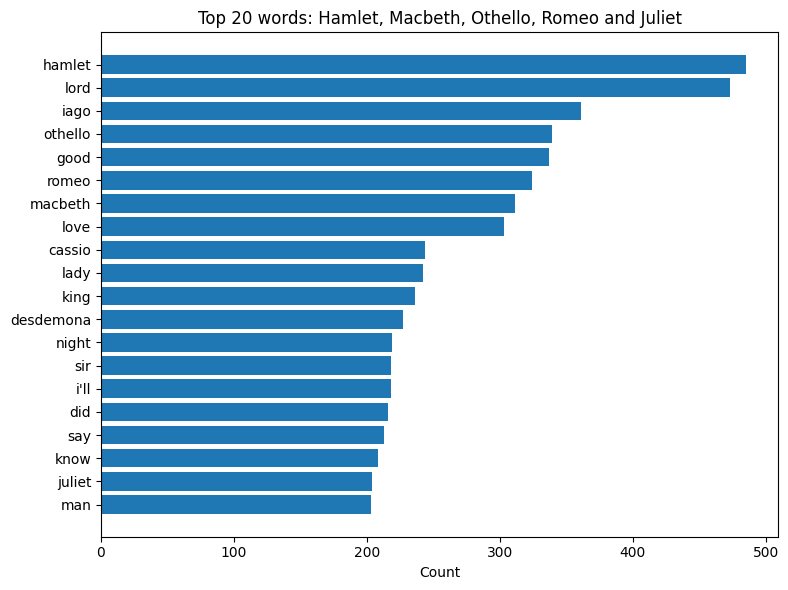

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

top = pd.read_csv('outputs/tragedies_top20-00000-of-00001.csv')
top = top.sort_values('count')

plt.figure(figsize=(8, 6))
plt.barh(top['word'], top['count'])
plt.title('Top 20 words: Hamlet, Macbeth, Othello, Romeo and Juliet')
plt.xlabel('Count')
plt.tight_layout()
plt.show()
